# Case study 4: Population inference with simulated data

This notebook produces the figures and the numbers for Case study 4 of the paper. We infer the binary fraction and the distributions of period, eccentricity and companion mass of a simulated population of 256 stars, about 40% of which have a companion, from radial velocities alone. The posterior samples of each star come from the script `population_posteriors.py`, which we run on a cluster with MPI (`../slurm/population.sbatch`). It runs the rejection sampler on every star with one shared library of $10^7$ prior samples. For stars with fewer than 1024 samples, it reruns it with a shared library of $10^8$ prior samples, and if that is still not enough, it continues with MCMC (samples in a single period mode) or nested sampling (samples in several period modes, or MCMC that does not converge). Here we combine the posterior samples of all stars in a hierarchical model (a mixture of binaries and constant-velocity stars) by reweighting the samples from the interim prior to the population model.

This is an adaptation of the case study `population-binary-fraction.ipynb` in the `harv` documentation, and the nested sampling follows Case study 3 (`nested-sampling.ipynb`). The script `simulate_population.py` writes the simulated data to `../data/population/`, and `population_posteriors.py` writes the posterior samples to `../data/population/cache/`. This notebook writes the figures `../paper/figures/cs4-population.pdf` and `../paper/figures/cs4-rv-examples.pdf`. All seeds are fixed.

In [1]:
import jax
import numpyro

# Enable float64 before importing harv:
jax.config.update("jax_enable_x64", True)
numpyro.set_host_device_count(4)

In [16]:
from pathlib import Path

import harv
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import numpyro.distributions as dist
from harv.kepler import masses
from harv.kepler.orbits import rv_at_times
from harv.samplers.samples import pad_and_stack_samples
from jax.scipy.special import logsumexp
from numpyro.infer import MCMC, NUTS
from population_posteriors import (
    M_max,
    model,
    prior,
    read_data,
    read_posteriors,
    sigma_v0,
)
from unxt import Q

%matplotlib inline
print(f"harv {harv.__version__}, jax {jax.__version__}, numpyro {numpyro.__version__}")
print(jax.devices())

harv 0.0.2.dev238+g4d7e5d20a, jax 0.12.0.1, numpyro 0.22.0
[CpuDevice(id=0), CpuDevice(id=1), CpuDevice(id=2), CpuDevice(id=3)]


In [3]:
figure_path = Path("..").resolve() / "paper" / "figures"
figure_path.mkdir(exist_ok=True)

## Data

Each row of the table is one star: the data, the true parameters (which we use only for comparison), and an observed primary mass $M_1$. The data columns are padded with NaN to 12 epochs, and `n_epochs` is the number of epochs of each star. The table metadata holds the population parameters, including the uncertainty of $M_1$.

In [5]:
tbl, rv_data, n_epochs = read_data()
truth = tbl.meta
print(
    f"{len(tbl)} stars, {tbl['is_binary'].sum()} binaries, "
    f"{n_epochs.min()} to {n_epochs.max()} epochs per star"
)

256 stars, 102 binaries, 3 to 12 epochs per star


## Interim prior

The interim prior is uniform in $\ln P$ between 0.5 and $10^4$ days, a normal distribution for the eccentricity with mean 0.1 and standard deviation 0.4 (truncated to $[0, 1)$), and uniform in the phase and argument of pericenter. The linear parameters have the default Gaussian priors with $\sigma_{K,0} = 30~{\rm km~s^{-1}}$ and $\sigma_{v_0} = 50~{\rm km~s^{-1}}$. The interim prior is nonzero everywhere the population model below is nonzero. It is defined in `population_posteriors.py`, and we import it from there, so that the importance weights below use the same prior as the sampling.

## Posterior samples of each star

The script `population_posteriors.py` runs the rejection sampler on every star with one shared library of $J = 10^7$ prior samples, and keeps at most $M_{\rm max} = 1024$ samples per star. For stars with fewer than $M_{\rm max}$ samples, it reruns the rejection sampler with a shared library of $10^8$ prior samples, and $\ln Z_{\rm int}$ and $J_{\rm eff}$ of these stars come from this larger run. If a star still has fewer than $M_{\rm max}$ samples and all samples lie in one period mode, it continues with 4 chains of NUTS initialized from the rejection samples, and keeps $M_{\rm max}$ MCMC samples if $\hat{R} < 1.2$ for all parameters. Stars with samples in several period modes, or with $\hat{R} \geq 1.2$, go to the nested slice sampler from `blackjax`, following Case study 3 with 10,000 live points. We draw $M_{\rm max}$ samples from its weighted dead points, and for each we draw the linear parameters ($K$ and $v_0$) from their conditional posterior pdf given the nonlinear parameters, as the rejection sampler does. We keep $\ln Z_{\rm int}$ from the rejection sampler (see the next section), and print the nested sampling estimate for comparison.

Each MPI rank reuses the compiled code for stars with the same number of epochs, so we report the run time of the rejection sampler with $10^7$ prior samples only for stars that were not the first with their number of epochs on their rank. The table lists the stars with fewer than $M_{\rm max}$ samples from the first run, with the true period for comparison.

In [6]:
posteriors, info = read_posteriors(len(tbl))
outcome = np.asarray(info["outcome"])
ln_Z_int = np.asarray(info["ln_Z_int"])
J_eff = np.asarray(info["J_eff"])
n_samples = np.array([s.n_samples for s in posteriors])
n_1e7 = np.asarray(info["n_samples_1e7"])

warm = ~np.asarray(info["first"])
for m in np.unique(n_epochs):
    t = np.asarray(info["time_1e7"])[(n_epochs == m) & warm]
    print(f"{m:2d} epochs: median {np.median(t):.2f} s per star ({len(t)} stars)")
print(
    f"{(n_1e7 == M_max).sum()} stars with {M_max} samples, "
    f"{(n_1e7 <= 3).sum()} with at most 3, "
    f"{((n_1e7 > 3) & (n_1e7 < M_max)).sum()} in between\n"
)

for o in ["rejection 1e7", "rejection 1e8", "MCMC", "nested"]:
    sel = outcome == o
    print(
        f"{o:>14}: {sel.sum():3d} stars ({tbl['is_binary'][sel].sum()} binaries), "
        f"{(n_samples[sel] == M_max).sum()} with {M_max} samples, "
        f"median {np.median(np.asarray(info['time_total'])[sel]):.0f} s per star"
    )

median_P = np.array([np.median(s["period"].to_value("day")) for s in posteriors])
follow = info[n_1e7 < M_max]
follow.remove_columns(["time_1e7", "first"])
follow.add_column(np.flatnonzero(n_1e7 < M_max), name="star", index=0)
follow["median_P"] = median_P[n_1e7 < M_max]
follow["true_P"] = np.asarray(tbl["period"])[n_1e7 < M_max]
for col in follow.itercols():
    if col.dtype.kind == "f":
        col.info.format = ".4g"
follow.pprint_all()

 3 epochs: median 59.57 s per star (15 stars)
 4 epochs: median 58.45 s per star (9 stars)
 5 epochs: median 62.84 s per star (11 stars)
 6 epochs: median 58.94 s per star (11 stars)
 7 epochs: median 65.86 s per star (11 stars)
 8 epochs: median 64.32 s per star (11 stars)
 9 epochs: median 64.03 s per star (13 stars)
10 epochs: median 61.00 s per star (13 stars)
11 epochs: median 67.56 s per star (15 stars)
12 epochs: median 27.94 s per star (15 stars)
182 stars with 1024 samples, 40 with at most 3, 34 in between

 rejection 1e7: 182 stars (30 binaries), 182 with 1024 samples, median 70 s per star
 rejection 1e8:  11 stars (9 binaries), 11 with 1024 samples, median 527 s per star
          MCMC:  30 stars (30 binaries), 30 with 1024 samples, median 599 s per star
        nested:  33 stars (33 binaries), 33 with 1024 samples, median 1045 s per star
star    outcome    ln_Z_int   J_eff   n_samples_1e7 J_eff_1e7 r_hat ln_Z_nested time_total median_P true_P
---- ------------- -------- ---

## Evidence for a companion

The mixture model below needs the evidence of each star under the binary model with the interim prior, $Z_{\rm int}$ (from the largest rejection run for each star), and under the constant-velocity model, $Z_{\rm single}$, which we compute as in Case study 1. In Case study 3, the estimates of $\ln Z_{\rm int}$ were unreliable for sources with $J_{\rm eff} \sim 1$. Here we check that those stars are fit much better with a companion than without, so an error in $\ln Z_{\rm int}$ does not change how they enter the mixture, and that the stars for which the two models are comparable have $J_{\rm eff} \gg 1$.

In [7]:
def ln_gaussian(data, extra_cov):
    y, err = data.rv.to_value("km/s"), data.rv_err.to_value("km/s")
    mvn = dist.MultivariateNormal(
        loc=jnp.zeros(len(y)), covariance_matrix=jnp.diag(err**2) + extra_cov
    )
    return mvn.log_prob(y)


ln_Z_single = np.array([ln_gaussian(data, sigma_v0**2) for data in rv_data])
ln_B = ln_Z_int - ln_Z_single
close = np.abs(ln_B) < 5
print(
    f"{(J_eff < 3).sum()} stars with J_eff < 3: smallest ln B = {ln_B[J_eff < 3].min():.0f}"
)
print(f"{close.sum()} stars with |ln B| < 5: smallest J_eff = {J_eff[close].min():.3g}")

23 stars with J_eff < 3: smallest ln B = 1466
159 stars with |ln B| < 5: smallest J_eff = 1.95e+05


## Importance weights for the population model

The population model for the binaries is a truncated normal distribution in each of $\log_{10} P$ (between 5 and 1000 days, the range of the simulated binaries), $e$ (between 0 and 1), and $\log_{10} M_2$ (between 0.1 and $1~M_\odot$), with hyperparameters $\boldsymbol{\alpha}$. The posterior samples are in $(P, e, K)$, so we convert $K$ to $M_2$ with the mass function, drawing $M_1$ from its measurement and $\cos i$ from a uniform distribution once for each sample. The importance weight of sample $k$ of star $n$ is

$$
w_{nk}(\boldsymbol{\alpha}) = \frac{p(P_{nk}, e_{nk}, M_{2,nk} \mid \boldsymbol{\alpha})}{p_{\rm int}(P_{nk}, e_{nk}, K_{nk})} \left|\frac{\partial M_2}{\partial K}\right|_{nk} ,
$$

and is zero outside the box in $P$ and $M_2$. The interim prior on $K$ is a zero-mean Gaussian, so after `wrap_angles` makes $K$ positive, the interim density of $K$ is twice that Gaussian. Samples outside the box (and the padding) get placeholder values inside the box, so that the gradients of the population model stay finite; their weights are zero.

In [8]:
P_box, M2_box = (5.0, 1000.0), (0.1, 1.0)  # day, Msun
names = ["mu_logP", "sigma_logP", "mu_e", "sigma_e", "mu_logM2", "sigma_logM2"]


def importance_inputs(P, e, K, M1, sin_i):
    """P, e, M2, ln(|dM2/dK| / p_int(P, e, K)) and whether in the box, for K > 0."""
    mf = masses.binary_mass_function(Q(P, "day"), Q(K, "km/s"), e)
    M2 = np.asarray(
        masses.companion_mass_from_mass_function(mf, Q(M1, "Msun"), sin_i).to_value(
            "Msun"
        )
    )
    ln_dM2_dK = np.log(M2 / K) - np.log1p(-2 / 3 * M2 / (M1 + M2))
    K_prior = prior.linear_priors["rv_semiamp"](
        {"period": Q(P, "day"), "eccentricity": e}
    )
    ln_p_int = (
        prior.nonlinear_priors["period"].distribution.log_prob(P)
        + prior.nonlinear_priors["eccentricity"].log_prob(e)
        + np.log(2)
        + K_prior.distribution.log_prob(K)
    )
    inside = (P > P_box[0]) & (P < P_box[1]) & (M2 > M2_box[0]) & (M2 < M2_box[1])
    return (
        np.where(inside, P, 100.0),
        np.where(inside, e, 0.5),
        np.where(inside, M2, 0.5),
        np.where(inside, ln_dM2_dK - ln_p_int, 0.0),
        inside,
    )


def truncnorm_log10(x, mu, sigma, box):
    """ln p(x) for a normal distribution in log10(x), truncated to the box in x."""
    low, high = np.log10(box)
    log10_x = jnp.log10(x)
    return dist.TruncatedNormal(mu, sigma, low=low, high=high).log_prob(
        log10_x
    ) - jnp.log(x * np.log(10))


def ln_weights(alpha, P, e, M2, ln_term, inside):
    ln_pop = (
        truncnorm_log10(P, alpha["mu_logP"], alpha["sigma_logP"], P_box)
        + dist.TruncatedNormal(
            alpha["mu_e"], alpha["sigma_e"], low=0.0, high=1.0
        ).log_prob(e)
        + truncnorm_log10(M2, alpha["mu_logM2"], alpha["sigma_logM2"], M2_box)
    )
    return jnp.where(inside, ln_pop + ln_term, -jnp.inf)

We check the normalization: averaged over samples from the interim prior (with $K > 0$), the weights should be 1 for any $\boldsymbol{\alpha}$, because the population model integrates to 1 over the box. We draw $10^6$ prior samples, and $K$, $M_1$ and $\cos i$ for each, and compute the mean weight at the true $\boldsymbol{\alpha}$ and at a different one.

In [9]:
rng = np.random.default_rng(42)
n_check = 1_000_000
prior_samples = prior.sample(n_check, key=jax.random.key(0), model=model)
P = np.asarray(prior_samples["period"].to_value("day"))
e = np.asarray(prior_samples["eccentricity"].value)
K_prior = prior.linear_priors["rv_semiamp"]({"period": Q(P, "day"), "eccentricity": e})
K = np.abs(np.asarray(K_prior.distribution.sample(jax.random.key(1))))
M1 = np.asarray(
    dist.TruncatedNormal(
        truth["M1_mean"], truth["M1_std"], low=truth["M1_min"], high=truth["M1_max"]
    ).sample(jax.random.key(2), P.shape)
)
sin_i = np.sqrt(1 - rng.uniform(size=P.shape) ** 2)
check_inputs = importance_inputs(P, e, K, M1, sin_i)

other = dict(zip(names, [2.0, 0.5, 0.2, 0.3, -0.5, 0.4], strict=True))
for alpha in [{k: truth[k] for k in names}, other]:
    w = np.exp(ln_weights(alpha, *check_inputs))
    mean, err = w.mean(), w.std() / np.sqrt(w.size)
    print(f"mean weight {mean:.4f} +/- {err:.4f}")
    assert abs(mean - 1) < 5 * err

mean weight 1.0026 +/- 0.0039
mean weight 0.9951 +/- 0.0033


Now the inputs for the posterior samples. `pad_and_stack_samples` pads every star to the largest number of samples; $M_n$ counts all samples of star $n$, including those outside the box (they have zero weight but are still draws from the posterior under the interim prior).

In [10]:
stacked, is_sample = pad_and_stack_samples([s.wrap_angles() for s in posteriors])
# The padding is NaN, which the interim prior on K rejects. We replace it with P = 1 day,
# outside the box, so that it gets zero weight like the other samples outside the box.
P = np.where(is_sample, stacked["period"].to_value("day"), 1.0)
e = np.where(is_sample, stacked["eccentricity"].value, 0.5)
K = np.where(is_sample, stacked["rv_semiamp"].to_value("km/s"), 1.0)
M1 = np.asarray(tbl["M1_obs"])[:, None] + truth["M1_err"] * rng.standard_normal(P.shape)
sin_i = np.sqrt(1 - rng.uniform(size=P.shape) ** 2)
inputs = importance_inputs(P, e, K, M1, sin_i)
ln_M_n = np.log(np.asarray(is_sample).sum(axis=1))
print(f"{inputs[-1].sum()} of {np.sum(is_sample)} samples are inside the box")

62728 of 262144 samples are inside the box


## Hierarchical model

The likelihood of the data $\boldsymbol{y}_n$ of star $n$ is a mixture of the binary population, with fraction $f$, and constant-velocity stars:

$$
p(\boldsymbol{y}_n \mid f, \boldsymbol{\alpha}) = f\,Z_{{\rm int},n}\,\frac{1}{M_n}\sum_k w_{nk}(\boldsymbol{\alpha}) + (1 - f)\,Z_{{\rm single},n} .
$$

We use uniform priors on $f$ and on the hyperparameters, and sample with NUTS.

In [11]:
def population_model(P, e, M2, ln_term, inside):
    f = numpyro.sample("f", dist.Uniform(0.0, 1.0))
    alpha = {
        "mu_logP": numpyro.sample("mu_logP", dist.Uniform(-2.0, 8.0)),
        "sigma_logP": numpyro.sample("sigma_logP", dist.Uniform(0.1, 5.0)),
        "mu_e": numpyro.sample("mu_e", dist.Uniform(0.05, 0.95)),
        "sigma_e": numpyro.sample("sigma_e", dist.Uniform(0.05, 0.5)),
        "mu_logM2": numpyro.sample("mu_logM2", dist.Uniform(-1.0, np.log10(2.0))),
        "sigma_logM2": numpyro.sample("sigma_logM2", dist.Uniform(0.05, 1.5)),
    }
    ln_w = ln_weights(alpha, P, e, M2, ln_term, inside)
    ln_binary = jnp.log(f) + ln_Z_int + logsumexp(ln_w, axis=1) - ln_M_n
    ln_single = jnp.log1p(-f) + ln_Z_single
    numpyro.factor("ln_L", jnp.logaddexp(ln_binary, ln_single).sum())


pop_mcmc = MCMC(
    NUTS(population_model),
    num_warmup=1000,
    num_samples=1000,
    num_chains=4,
    progress_bar=False,
)
pop_mcmc.run(jax.random.key(8675309), *inputs)
pop_mcmc.print_summary()
pop = pop_mcmc.get_samples()

for k in ["f", *names]:
    lo, med, hi = np.percentile(pop[k], [16, 50, 84])
    true = truth["binary_fraction" if k == "f" else k]
    print(f"{k:>12}: {med:.3f} -{med - lo:.3f} +{hi - med:.3f} (true {true:.3f})")


                   mean       std    median      5.0%     95.0%     n_eff     r_hat
            f      0.39      0.03      0.39      0.34      0.44   3293.63      1.00
         mu_e      0.38      0.03      0.38      0.33      0.42   2490.89      1.00
     mu_logM2     -0.08      0.16     -0.13     -0.29      0.19    826.76      1.01
      mu_logP      5.35      1.60      5.47      3.03      7.94    915.06      1.00
      sigma_e      0.17      0.03      0.17      0.12      0.22   1882.98      1.00
  sigma_logM2      0.28      0.10      0.26      0.13      0.42   1007.39      1.00
   sigma_logP      2.51      0.82      2.54      0.96      3.72    705.64      1.00

Number of divergences: 10
           f: 0.385 -0.031 +0.029 (true 0.398)
     mu_logP: 5.469 -2.010 +1.688 (true 5.030)
  sigma_logP: 2.535 -0.883 +0.776 (true 2.280)
        mu_e: 0.379 -0.028 +0.027 (true 0.400)
     sigma_e: 0.166 -0.025 +0.034 (true 0.150)
    mu_logM2: -0.131 -0.103 +0.231 (true -0.046)
 sigma_logM2: 0.

The effective sample size of the weights of each star (at the posterior median of $\boldsymbol{\alpha}$) tells us whether its samples resolve the posterior under the population model. We print it for the stars with samples inside the box.

In [12]:
alpha_med = {k: np.median(pop[k]) for k in names}
w = np.exp(np.asarray(ln_weights(alpha_med, *inputs)))
has = inputs[-1].any(axis=1)
ess = w[has].sum(axis=1) ** 2 / (w[has] ** 2).sum(axis=1)
print(
    f"{has.sum()} stars: ESS of the weights from {ess.min():.1f} to {ess.max():.0f}, "
    f"{(ess < 10).sum()} below 10"
)

253 stars: ESS of the weights from 1.0 to 854, 100 below 10


## Figure

The posterior pdf of $f$, and the population distributions for 512 posterior samples of $\boldsymbol{\alpha}$ (median and 16th to 84th percentiles at each point), compared with the true distributions and the interim prior. The densities are in $\log_{10} P$ and $\log_{10} M_2$.

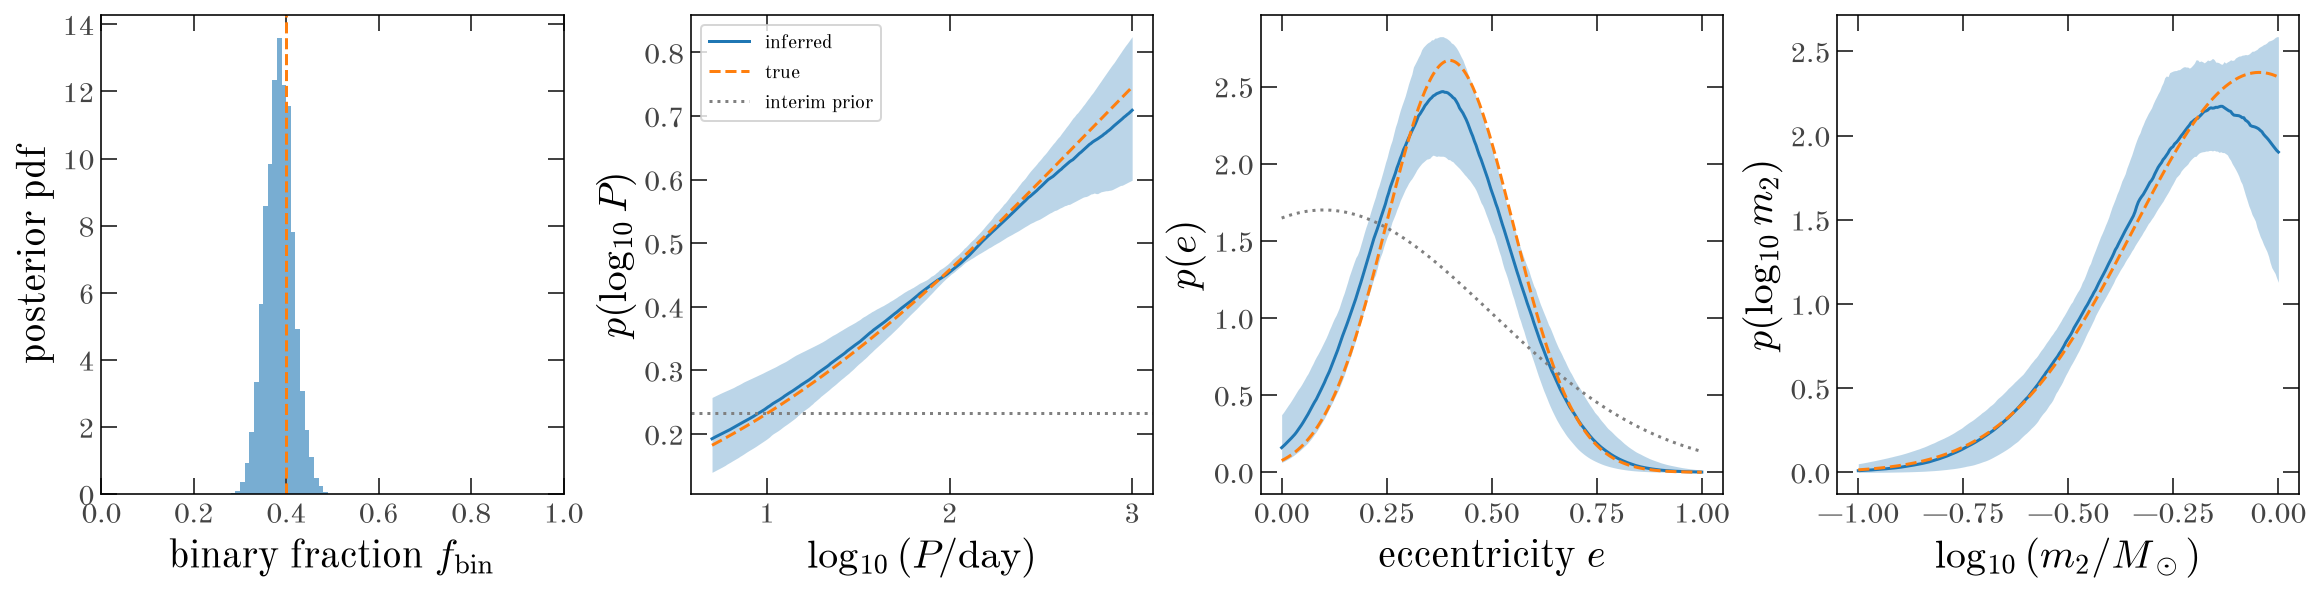

In [13]:
idx = np.random.default_rng(123).choice(len(pop["f"]), 512, replace=False)
fig, axes = plt.subplots(1, 4, figsize=(16, 4), layout="constrained")

ax = axes[0]
ax.hist(
    pop["f"], bins=np.linspace(0, 1, 101), density=True, color="tab:blue", alpha=0.6
)
ax.axvline(truth["binary_fraction"], color="tab:orange", ls="--", marker="")
ax.set_xlim(0, 1)
ax.set_xlabel(r"binary fraction $f_{\rm bin}$")
ax.set_ylabel("posterior pdf")

panels = [
    ("logP", np.log10(P_box), r"$\log_{10}(P/{\rm day})$", r"$p(\log_{10} P)$"),
    ("e", (0.0, 1.0), "eccentricity $e$", "$p(e)$"),
    ("logM2", np.log10(M2_box), r"$\log_{10}(m_2/M_\odot)$", r"$p(\log_{10} m_2)$"),
]
for ax, (name, (low, high), xlabel, ylabel) in zip(axes[1:], panels, strict=True):
    x = np.linspace(low, high, 256)
    ln_p = dist.TruncatedNormal(
        pop[f"mu_{name}"][idx, None],
        pop[f"sigma_{name}"][idx, None],
        low=low,
        high=high,
    ).log_prob(x)
    lo, med, hi = np.percentile(np.exp(ln_p), [16, 50, 84], axis=0)
    ax.fill_between(x, lo, hi, color="tab:blue", alpha=0.3, lw=0)
    ax.plot(x, med, color="tab:blue", marker="", label="inferred")
    true = dist.TruncatedNormal(
        truth[f"mu_{name}"], truth[f"sigma_{name}"], low=low, high=high
    ).log_prob(x)
    ax.plot(x, np.exp(true), color="tab:orange", ls="--", marker="", label="true")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)

# Interim prior: uniform in ln P (so in log10 P) over 0.5 to 1e4 days, and the
# truncated normal in e.
P_range = np.log10([0.5, 1e4])
axes[1].axhline(
    1 / np.ptp(P_range), color="0.5", ls=":", marker="", label="interim prior"
)
x = np.linspace(0, 1, 256)
axes[2].plot(
    x,
    np.exp(prior.nonlinear_priors["eccentricity"].log_prob(x)),
    color="0.5",
    ls=":",
    marker="",
)
axes[1].legend(loc="upper left")
fig.savefig(figure_path / "cs4-population.pdf")

## Figure: example stars

One star from each outcome of the sampling procedure above. Left: the data (black), 64 posterior orbits (blue) and the true orbit (orange; a constant velocity for a single star). Right: the period and eccentricity of all posterior samples over the range of the interim prior, and the true values (orange). The MCMC samples are in one narrow mode, so we zoom in on it with an inset.

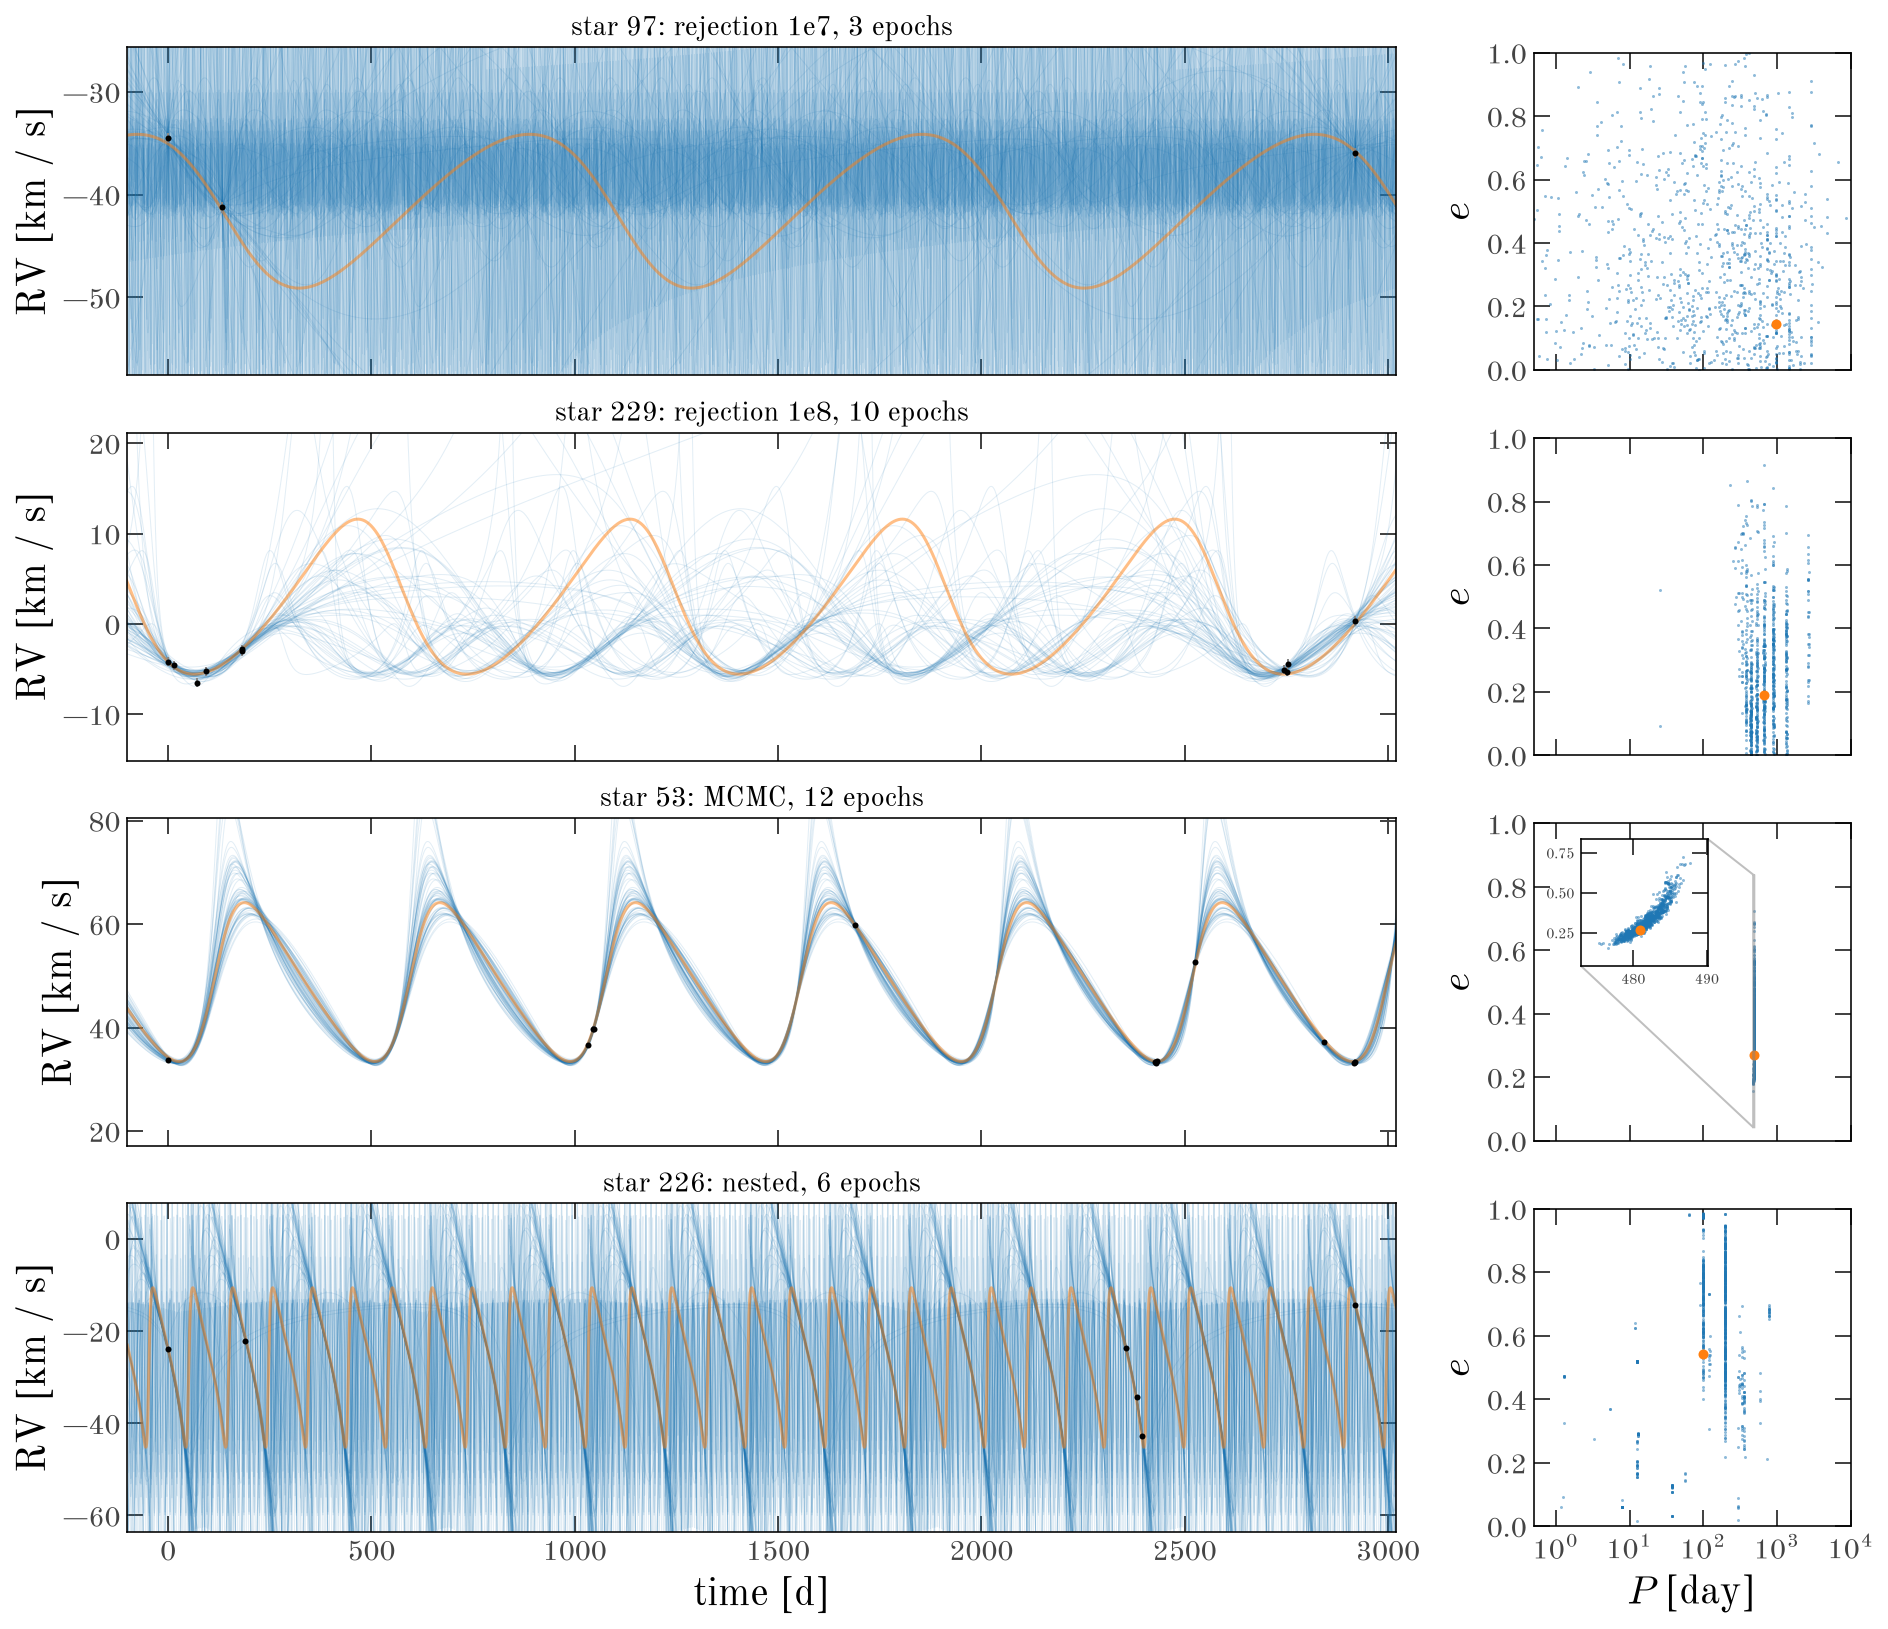

In [29]:
# One star from each outcome. The MCMC chains of star 35 are stuck in a local mode (the
# true orbit fits the data better than all of its samples), so we show star 53.
examples = [
    ("rejection 1e7", 97),
    ("rejection 1e8", 229),
    ("MCMC", 53),
    ("nested", 226),
]
rng = np.random.default_rng(321)
fig, axes = plt.subplots(
    len(examples),
    2,
    figsize=(13, 2.8 * len(examples)),
    width_ratios=[4, 1],
    layout="constrained",
    squeeze=False,
    sharex="col",
)
for (ax, ax_Pe), (o, n) in zip(axes, examples, strict=True):
    s, data, true = posteriors[n], rv_data[n], tbl[n]
    # A random subset: plot_rv draws the first rows, and MCMC chains are stored in order.
    s_plot = s[rng.choice(s.n_samples, min(s.n_samples, 64), replace=False)]
    harv.plot.plot_rv(
        s_plot,
        data=data,
        n_samples=128,
        plot_kwargs={"color": "tab:blue", "rasterized": True},
        data_plot_kwargs={"color": "k", "markersize": 3},
        ax=ax,
    )
    if ax.get_legend() is not None:
        ax.get_legend().remove()

    # The true orbit (a constant velocity for a single star).
    if true["is_binary"]:
        P_true = Q(true["period"], "day")
        t = harv.plot.get_time_grid(data.time, P_true)
        rv_true = rv_at_times(
            t,
            period=P_true,
            eccentricity=true["eccentricity"],
            time_peri=Q(true["time_peri"], "day"),
            arg_peri=Q(true["arg_peri"], "rad"),
            rv_semiamp=Q(true["K"], "km/s"),
            v_sys=Q(true["v_sys"], "km/s"),
        )
        ax.plot(
            t.to_value("day"),
            rv_true.to_value("km/s"),
            color="tab:orange",
            alpha=0.5,
            marker="",
            rasterized=True,
        )
    else:
        ax.axhline(true["v_sys"], color="tab:orange", alpha=0.5, marker="")

    # Zoom to the data: with 3 epochs, the posterior orbits reach hundreds of km/s.
    rv = data.rv.to_value("km/s")
    # pad = 0.5 * np.ptp(rv) + 1
    # ax.set_ylim(rv.min() - pad, rv.max() + pad)
    _tmp = rv_true.to_value("km/s")
    pad = 0.5 * np.ptp(_tmp) + 1
    ax.set_ylim(_tmp.min() - pad, _tmp.max() + pad)
    ax.set_xlim(-100, 3020)  # the 8-year baseline
    ax.set_title(f"star {n}: {o}, {n_epochs[n]} epochs", fontsize=14)

    # Period and eccentricity of all samples, over the range of the interim prior.
    P, e = s["period"].to_value("day"), s["eccentricity"].value
    pe_axes = [ax_Pe]
    if o == "MCMC":  # the samples are in one narrow mode: zoom in with an inset
        ax_in = ax_Pe.inset_axes([0.15, 0.55, 0.4, 0.4])
        pe_axes.append(ax_in)
    for a in pe_axes:
        a.plot(
            P,
            e,
            ls="",
            marker="o",
            mew=0,
            ms=1.5,
            alpha=0.5,
            color="tab:blue",
            rasterized=True,
        )
        a.plot(true["period"], true["eccentricity"], marker="o", color="tab:orange")
    ax_Pe.set_xscale("log")
    ax_Pe.set_xlim(0.5, 1e4)
    ax_Pe.set_ylim(0, 1)
    ax_Pe.set_box_aspect(1)
    ax_Pe.set_xlabel(r"$P$ [day]")
    ax_Pe.set_ylabel(r"$e$")
    ax_Pe.set_xticks(10 ** np.arange(0, 4 + 1, 1))
    if o == "MCMC":
        ax_in.margins(0.2)
        ax_in.tick_params(labelsize=7)
        ax_in.locator_params(axis="x", nbins=2)
        ax_in.ticklabel_format(useOffset=False)
        ax_in.locator_params(axis="y", nbins=3)
        ax_Pe.indicate_inset_zoom(ax_in, edgecolor="0.5")

    for ax in axes[:-1, 0]:
        ax.set_xlabel("")
    for ax in axes[:-1, 1]:
        ax.set_xlabel("")
fig.savefig(figure_path / "cs4-rv-examples.pdf", dpi=300)